<a href="https://colab.research.google.com/github/ahmede9ka/Potato-Tomato-Leaf-Disease-Detection/blob/main/Computer_vision_Ahmed_Kallel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Install dependencies
!pip install scikit-image opencv-python-headless matplotlib seaborn scikit-learn tensorflow kaggle -q

In [ ]:
#Imports (FIXED)
import os, cv2, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from skimage.color import rgb2gray          # ← fixed: was skimage.feature
from skimage.feature import graycomatrix, graycoprops   # ← these two are correct
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import files
print("All imports OK")

All imports OK


In [ ]:
# Upload your kaggle.json API key
# Go to kaggle.com → Account → Create API Token → download kaggle.json
files.upload()  # upload kaggle.json when prompted

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download PlantVillage dataset
!kaggle datasets download -d abdallahalidev/plantvillage-dataset
!unzip -q plantvillage-dataset.zip -d plantvillage
print("Dataset ready!")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:22<00:00, 97.2MB/s]

Dataset ready!


In [ ]:
# Pick 4 classes and load images
DATA_DIR = "/content/plantvillage/plantvillage dataset/color"
IMG_SIZE = 128

# Choose your 4 classes (folder names inside the dataset)
CLASSES = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Potato___healthy",
    "Potato___Late_blight"
]

def load_images(data_dir, classes, img_size=128, max_per_class=300):
    images, labels = [], []
    for label, cls in enumerate(classes):
        folder = os.path.join(data_dir, cls)
        count = 0
        for fname in os.listdir(folder):
            if count >= max_per_class:
                break
            img = cv2.imread(os.path.join(folder, fname))
            if img is None:
                continue
            img = cv2.resize(img, (img_size, img_size))
            images.append(img)
            labels.append(label)
            count += 1
        print(f"  Loaded {count} images for '{cls}'")
    return np.array(images), np.array(labels)

images, labels = load_images(DATA_DIR, CLASSES)
print(f"\nTotal: {len(images)} images, {len(np.unique(labels))} classes")

  Loaded 300 images for 'Tomato___healthy'
  Loaded 300 images for 'Tomato___Early_blight'
  Loaded 152 images for 'Potato___healthy'
  Loaded 300 images for 'Potato___Late_blight'

Total: 1052 images, 4 classes


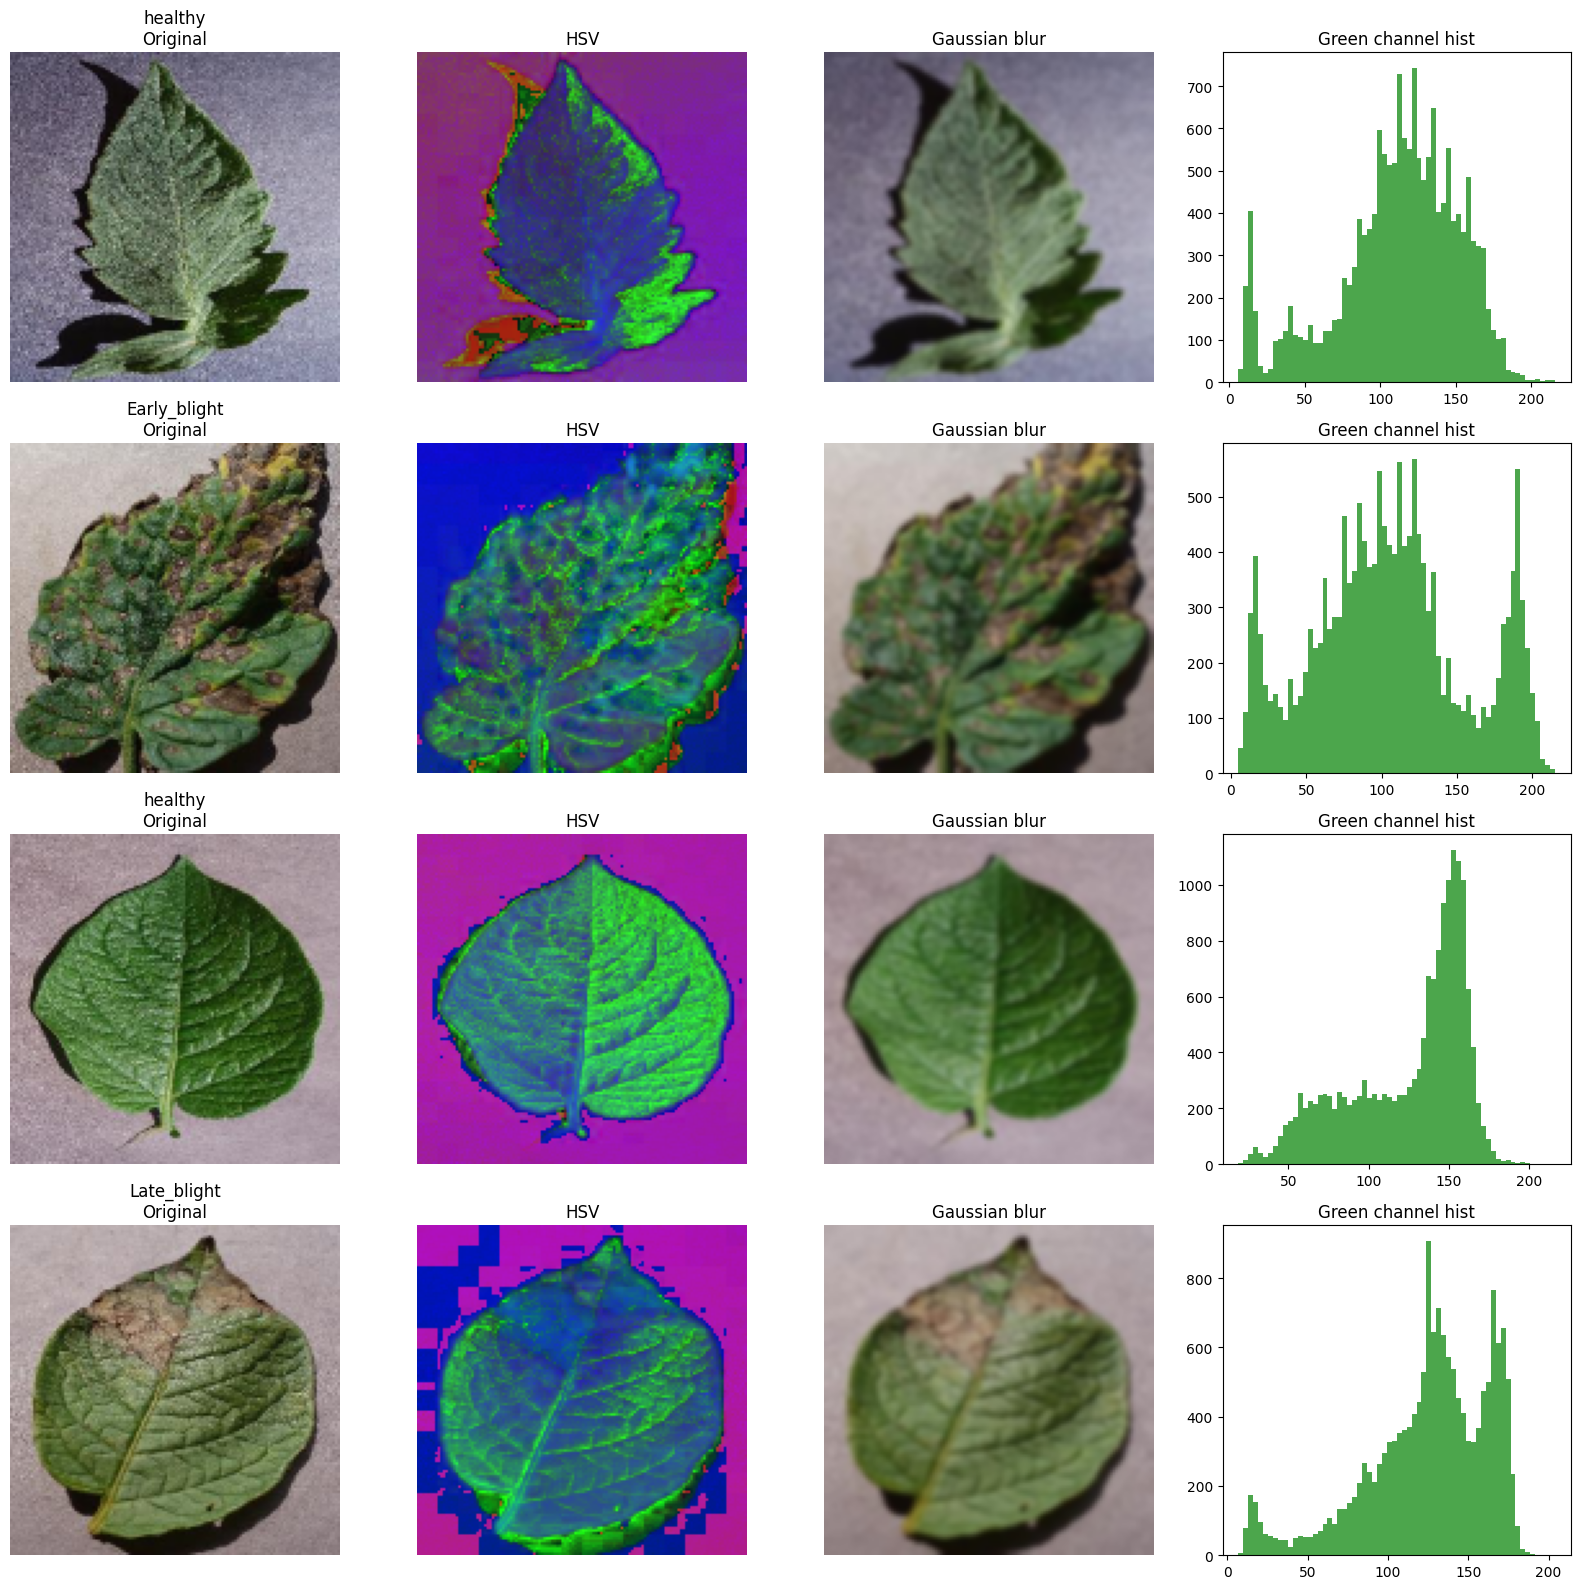

Preprocessing visualization saved


In [ ]:
#  Preprocessing: resize + HSV + Gaussian blur + histogram
def preprocess(img):
    # Already resized during loading
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    return img, hsv, blurred

# Visualize preprocessing on one sample per class
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(16, 4 * len(CLASSES)))
titles = ["Original", "HSV", "Blurred", "Histogram"]

for i, cls in enumerate(CLASSES):
    idx = np.where(labels == i)[0][0]
    orig, hsv, blurred = preprocess(images[idx])

    axes[i][0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
    axes[i][0].set_title(f"{cls.split('___')[1]}\nOriginal")
    axes[i][1].imshow(hsv)
    axes[i][1].set_title("HSV")
    axes[i][2].imshow(cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB))
    axes[i][2].set_title("Gaussian blur")

    # Histogram of green channel
    axes[i][3].hist(orig[:, :, 1].ravel(), bins=64, color="green", alpha=0.7)
    axes[i][3].set_title("Green channel hist")

    for ax in axes[i]:
        ax.axis("off") if ax != axes[i][3] else None

plt.tight_layout()
plt.savefig("preprocessing_results.png", dpi=100)
plt.show()
print("Preprocessing visualization saved")

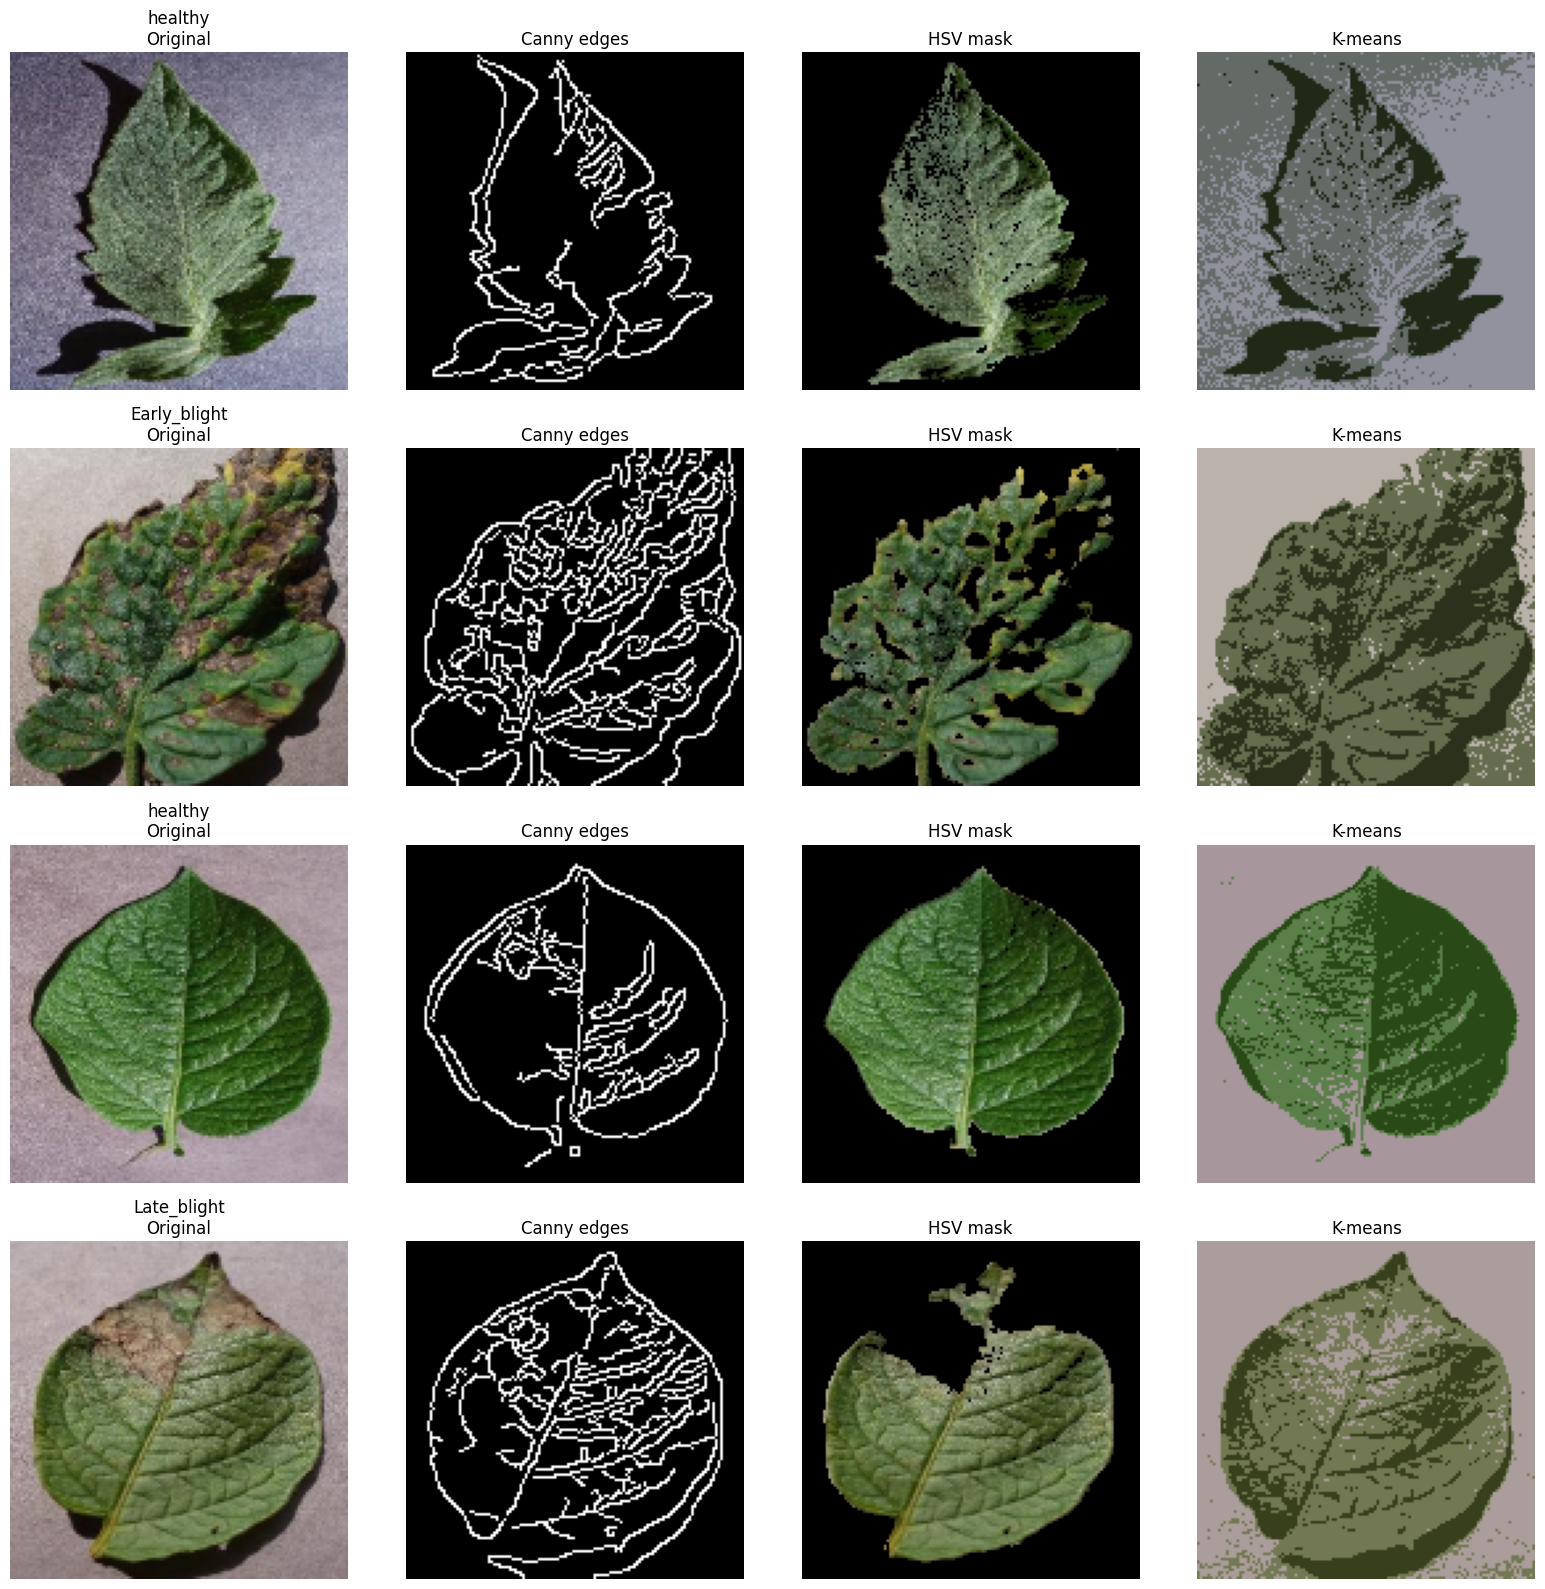

In [ ]:
# Segmentation: Canny edges + HSV thresholding + K-means
def segment_image(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Canny edge detection
    canny = cv2.Canny(blurred, 50, 150)

    # HSV color segmentation (isolate green leaf)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, np.array([25, 40, 40]), np.array([90, 255, 255]))
    hsv_seg = cv2.bitwise_and(img, img, mask=mask)

    # K-means clustering (3 clusters)
    Z = img.reshape((-1, 3)).astype(np.float32)
    _, labels_km, centers = cv2.kmeans(Z, 3, None,
        (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0),
        10, cv2.KMEANS_RANDOM_CENTERS)
    kmeans_seg = centers[labels_km.flatten()].reshape(img.shape).astype(np.uint8)

    return canny, hsv_seg, kmeans_seg

# Visualize segmentation on one image per class
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(16, 4 * len(CLASSES)))
for i, cls in enumerate(CLASSES):
    idx = np.where(labels == i)[0][0]
    img = images[idx]
    canny, hsv_seg, kmeans_seg = segment_image(img)

    axes[i][0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i][0].set_title(f"{cls.split('___')[1]}\nOriginal")
    axes[i][1].imshow(canny, cmap="gray")
    axes[i][1].set_title("Canny edges")
    axes[i][2].imshow(cv2.cvtColor(hsv_seg, cv2.COLOR_BGR2RGB))
    axes[i][2].set_title("HSV mask")
    axes[i][3].imshow(cv2.cvtColor(kmeans_seg, cv2.COLOR_BGR2RGB))
    axes[i][3].set_title("K-means")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig("segmentation_results.png", dpi=100)
plt.show()

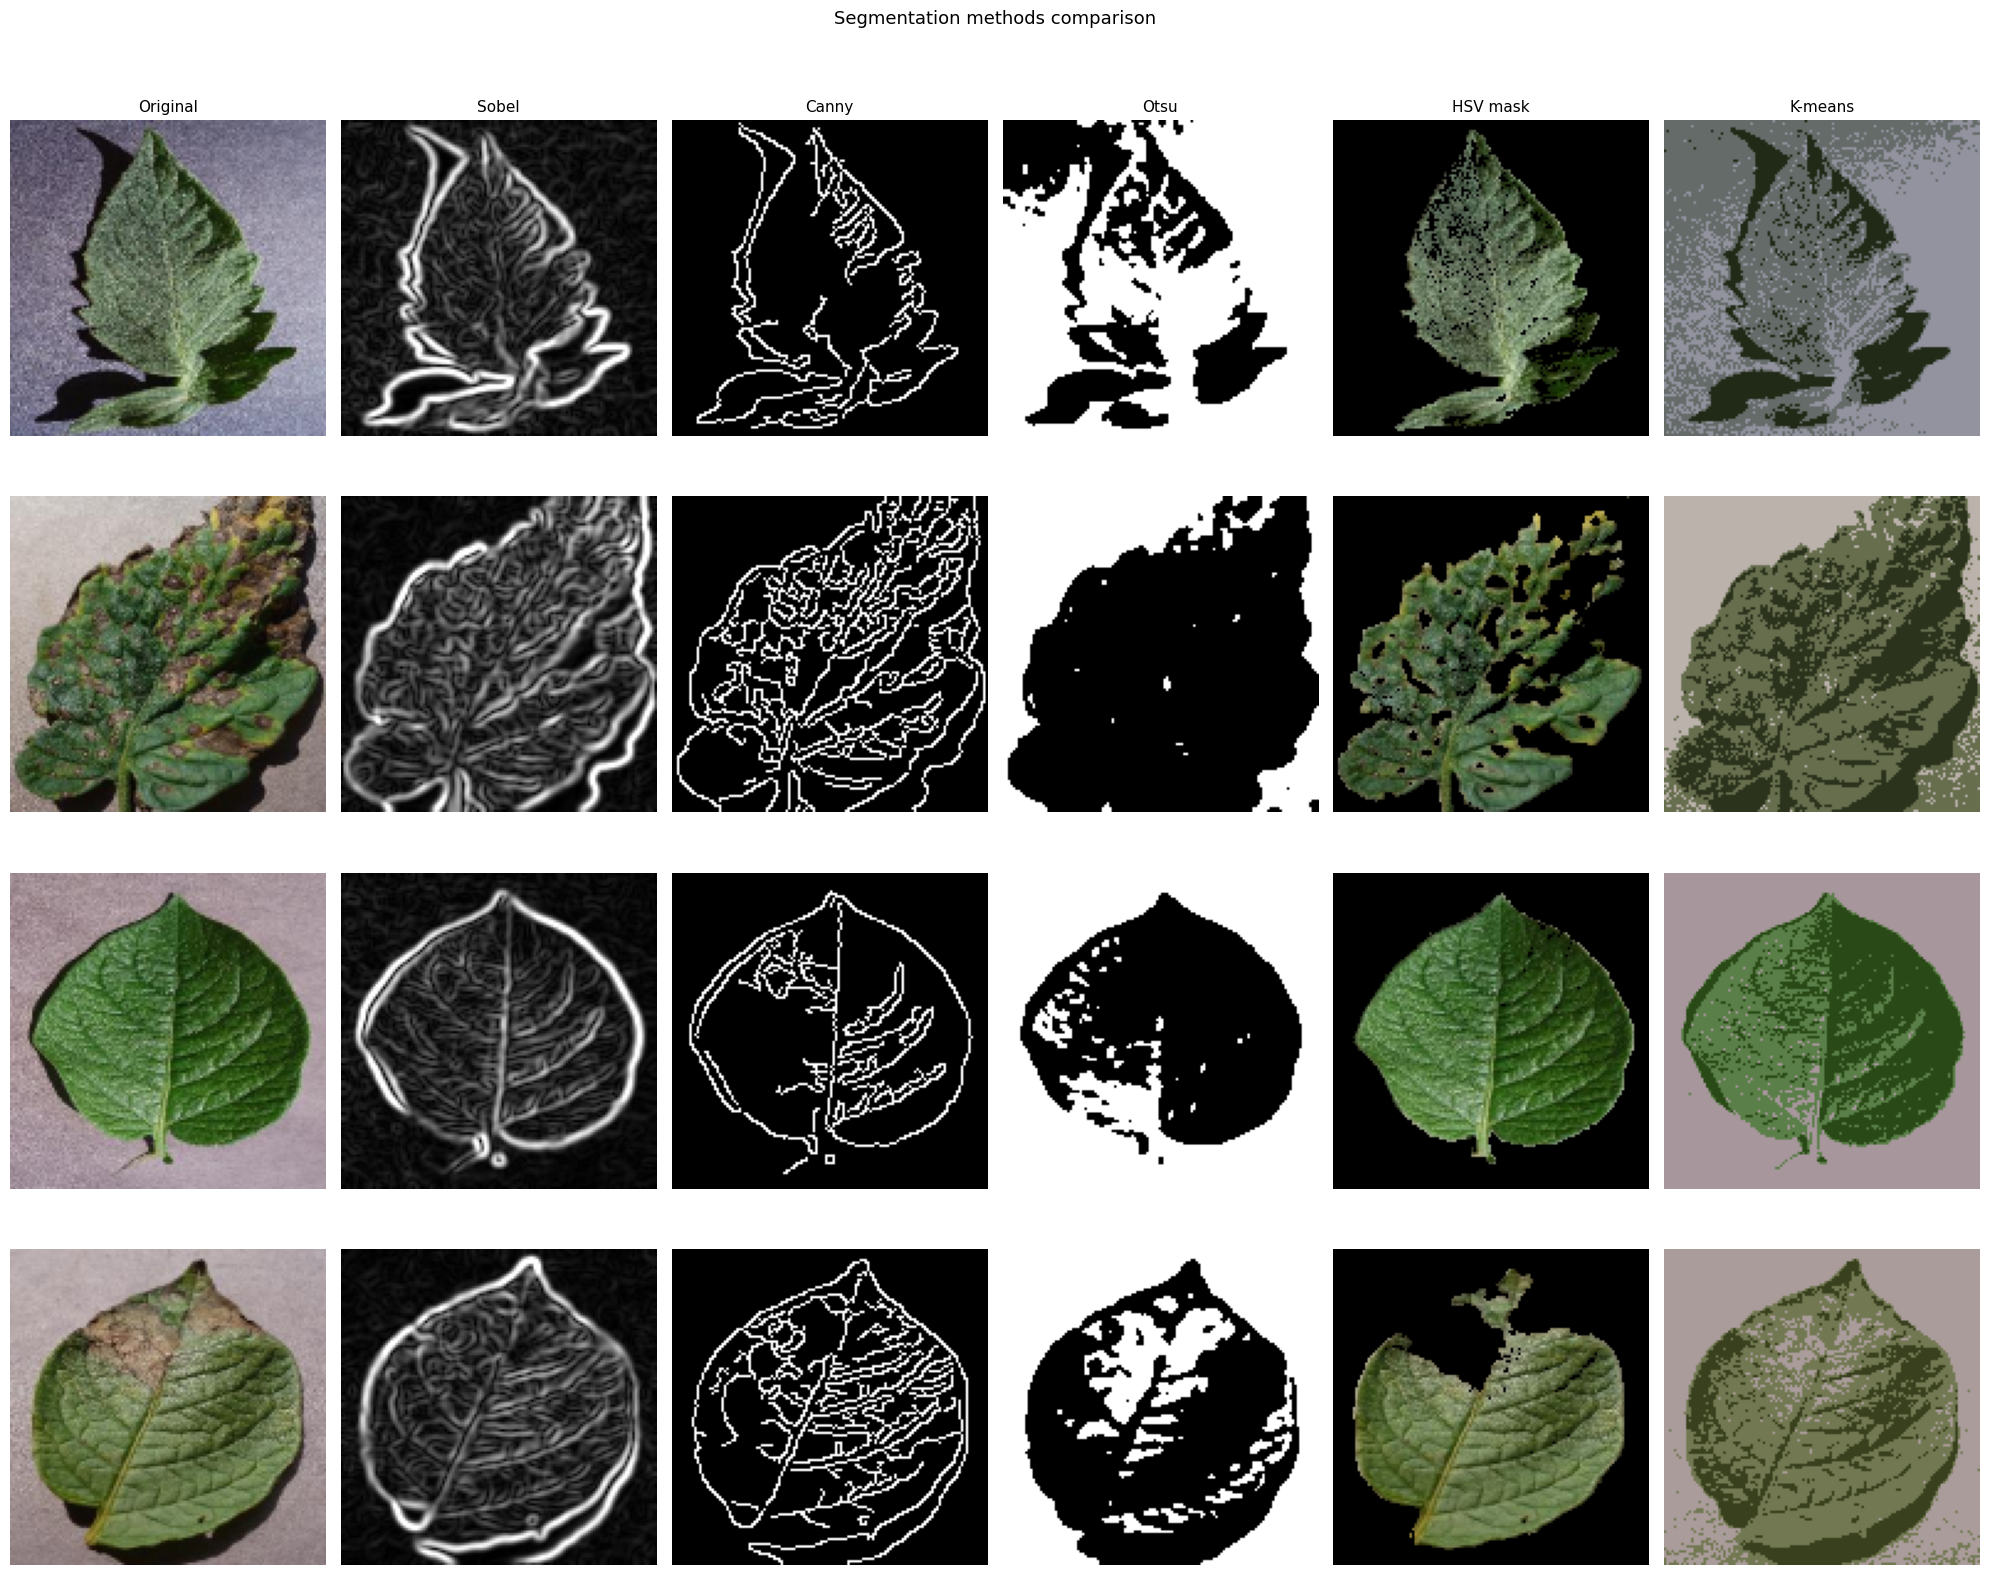

Saved: segmentation_comparison.png


In [ ]:
# Sobel + Otsu thresholding (add after existing segmentation cell)
def segment_full(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Sobel edges
    sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
    sobel = cv2.magnitude(sobel_x, sobel_y)
    sobel = np.uint8(np.clip(sobel, 0, 255))

    # Canny
    canny = cv2.Canny(blurred, 50, 150)

    # Otsu thresholding
    _, otsu = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # HSV color segmentation
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, np.array([25, 40, 40]), np.array([90, 255, 255]))
    hsv_seg = cv2.bitwise_and(img, img, mask=mask)

    # K-means
    Z = img.reshape((-1, 3)).astype(np.float32)
    _, km_labels, centers = cv2.kmeans(
        Z, 3, None,
        (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0),
        10, cv2.KMEANS_RANDOM_CENTERS
    )
    kmeans_seg = centers[km_labels.flatten()].reshape(img.shape).astype(np.uint8)

    return sobel, canny, otsu, hsv_seg, kmeans_seg


# Visualize all 5 methods side by side for one image per class
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(20, 4 * len(CLASSES)))
col_titles = ["Original", "Sobel", "Canny", "Otsu", "HSV mask", "K-means"]

for i, cls in enumerate(CLASSES):
    idx = np.where(labels == i)[0][0]
    img = images[idx]
    sobel, canny, otsu, hsv_seg, kmeans = segment_full(img)

    imgs_to_show = [
        (cv2.cvtColor(img, cv2.COLOR_BGR2RGB), "gray"),
        (sobel, "gray"),
        (canny, "gray"),
        (otsu, "gray"),
        (cv2.cvtColor(hsv_seg, cv2.COLOR_BGR2RGB), None),
        (cv2.cvtColor(kmeans, cv2.COLOR_BGR2RGB), None),
    ]

    for j, (im, cmap) in enumerate(imgs_to_show):
        axes[i][j].imshow(im, cmap=cmap)
        if i == 0:
            axes[i][j].set_title(col_titles[j], fontsize=11)
        axes[i][j].set_ylabel(cls.split("___")[1] if j == 0 else "", fontsize=9)
        axes[i][j].axis("off")

plt.suptitle("Segmentation methods comparison", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("segmentation_comparison.png", dpi=100, bbox_inches="tight")
plt.show()
print("Saved: segmentation_comparison.png")

In [ ]:
#  Extract color + GLCM texture + shape features
def extract_features(img):
    features = []

    # --- Color histograms (RGB + HSV) ---
    for channel in range(3):
        hist = cv2.calcHist([img], [channel], None, [32], [0, 256])
        features.extend(hist.flatten())
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    for channel in range(3):
        hist = cv2.calcHist([hsv], [channel], None, [32], [0, 256])
        features.extend(hist.flatten())

    # --- GLCM texture ---
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    glcm = graycomatrix(gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
        features.append(graycoprops(glcm, prop)[0, 0])

    # --- Shape features from HSV mask ---
    mask = cv2.inRange(hsv, np.array([25, 40, 40]), np.array([90, 255, 255]))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(largest)
        perimeter = cv2.arcLength(largest, True)
        circularity = (4 * np.pi * area / (perimeter ** 2)) if perimeter > 0 else 0
        features.extend([area, perimeter, circularity])
    else:
        features.extend([0, 0, 0])

    return np.array(features)

print("Extracting features... (this takes a minute)")
X = np.array([extract_features(img) for img in images])
y = labels
print(f"Feature vector shape: {X.shape}")

Extracting features... (this takes a minute)
Feature vector shape: (1052, 200)


In [ ]:
#  Train/test split + SVM + Random Forest
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# SVM
print("Training SVM...")
svm = SVC(kernel="rbf", C=10, gamma="scale")
svm.fit(X_train_sc, y_train)
svm_pred = svm.predict(X_test_sc)
svm_acc = accuracy_score(y_test, svm_pred)
print(f"SVM Accuracy: {svm_acc:.4f}")

# Random Forest
print("Training Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_sc, y_train)
rf_pred = rf.predict(X_test_sc)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Random Forest Accuracy: {rf_acc:.4f}")

Training SVM...
SVM Accuracy: 0.9810
Training Random Forest...
Random Forest Accuracy: 0.9810


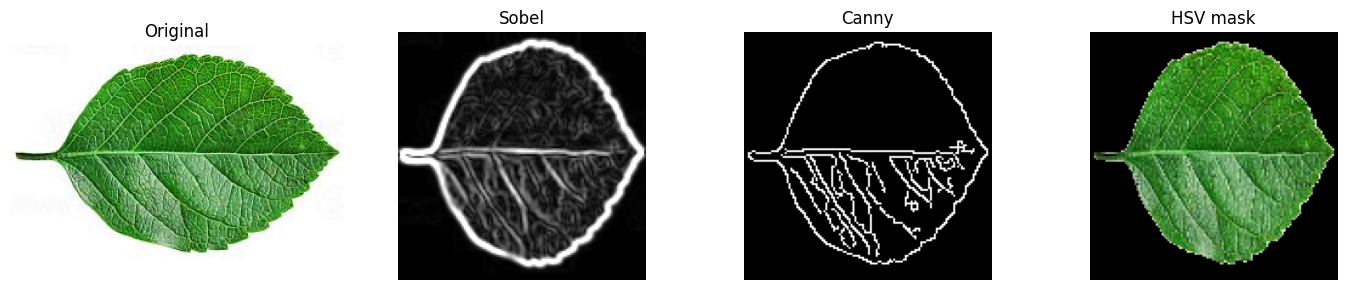

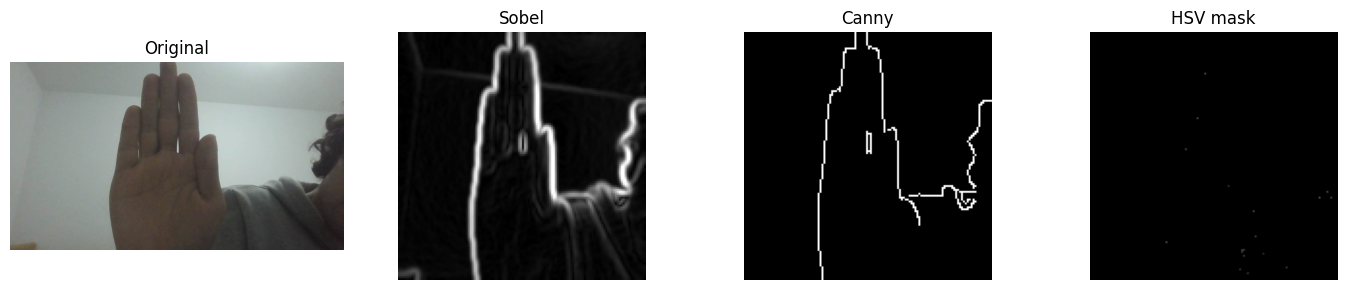

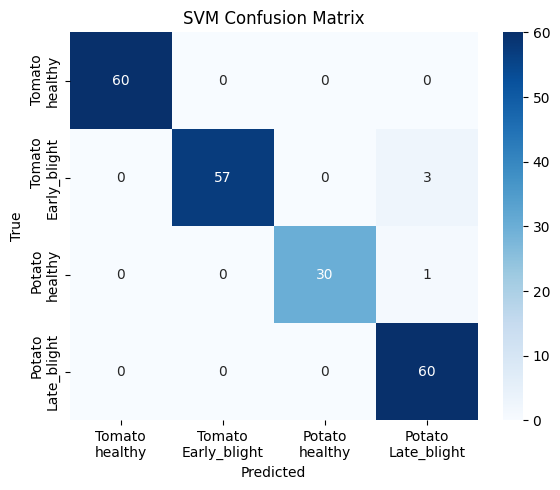

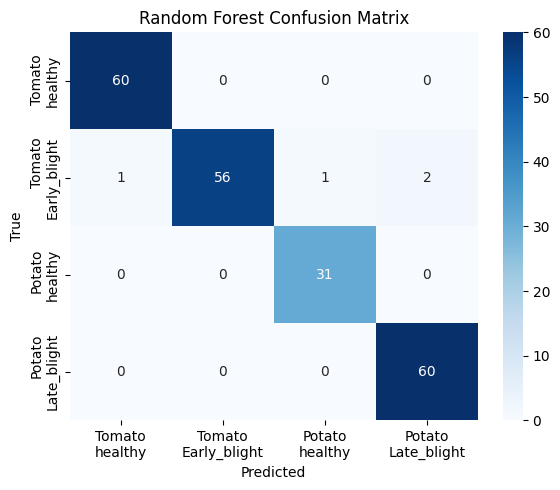


--- SVM Report ---
                       precision    recall  f1-score   support

     Tomato___healthy       1.00      1.00      1.00        60
Tomato___Early_blight       1.00      0.95      0.97        60
     Potato___healthy       1.00      0.97      0.98        31
 Potato___Late_blight       0.94      1.00      0.97        60

             accuracy                           0.98       211
            macro avg       0.98      0.98      0.98       211
         weighted avg       0.98      0.98      0.98       211


--- Random Forest Report ---
                       precision    recall  f1-score   support

     Tomato___healthy       0.98      1.00      0.99        60
Tomato___Early_blight       1.00      0.93      0.97        60
     Potato___healthy       0.97      1.00      0.98        31
 Potato___Late_blight       0.97      1.00      0.98        60

             accuracy                           0.98       211
            macro avg       0.98      0.98      0.98       211


In [ ]:
#  Full evaluation
class_names = [c.replace("___", "\n") for c in CLASSES]

def plot_confusion(y_true, y_pred, title, names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=names, yticklabels=names)
    plt.title(title)
    plt.ylabel("True")
    plt.xlabel("Predicted")
    plt.tight_layout()
    plt.savefig(f"{title.replace(' ','_')}.png", dpi=100)
    plt.show()

plot_confusion(y_test, svm_pred, "SVM Confusion Matrix", class_names)
plot_confusion(y_test, rf_pred, "Random Forest Confusion Matrix", class_names)

print("\n--- SVM Report ---")
print(classification_report(y_test, svm_pred, target_names=CLASSES))
print("\n--- Random Forest Report ---")
print(classification_report(y_test, rf_pred, target_names=CLASSES))

In [ ]:
#  Build and train a CNN
from tensorflow.keras.utils import to_categorical

# Normalize images
X_img = images / 255.0
y_cat = to_categorical(y, num_classes=len(CLASSES))

X_tr, X_te, y_tr, y_te = train_test_split(X_img, y_cat, test_size=0.2, random_state=42, stratify=y)

# CNN model
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation="relu", input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(128, (3,3), activation="relu"),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(CLASSES), activation="softmax")
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(X_tr, y_tr, epochs=15, batch_size=32,
                    validation_split=0.1, verbose=1)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,517,060 (24.86 MB)

 Trainable params: 6,517,060 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 27s 986ms/step - accuracy: 0.3016 - loss: 1.3988 - val_accuracy: 0.5529 - val_loss: 1.2448
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.5556 - loss: 1.0265 - val_accuracy: 0.5882 - val_loss: 0.8325
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.7765 - loss: 0.5858 - val_accuracy: 0.7882 - val_loss: 0.4828
Epoch 4/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8558 - loss: 0.4229 - val_accuracy: 0.8824 - val_loss: 0.3223
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 40s 970ms/step - accuracy: 0.8677 - loss: 0.3786 - val_accuracy: 0.8353 - val_loss: 0.3962
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8981 - loss: 0.2773 - val_accuracy: 0.8118 - val_loss: 0.5376
Epoch 7/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.9087 - loss: 0.2585 - val_accuracy: 0.8824 - val_loss: 0.2573
Epoch 8/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 23s 979ms/step - accuracy: 0.9339 - loss: 0.1760 - val_accuracy: 0.8941 - 

CNN Accuracy: 0.9621


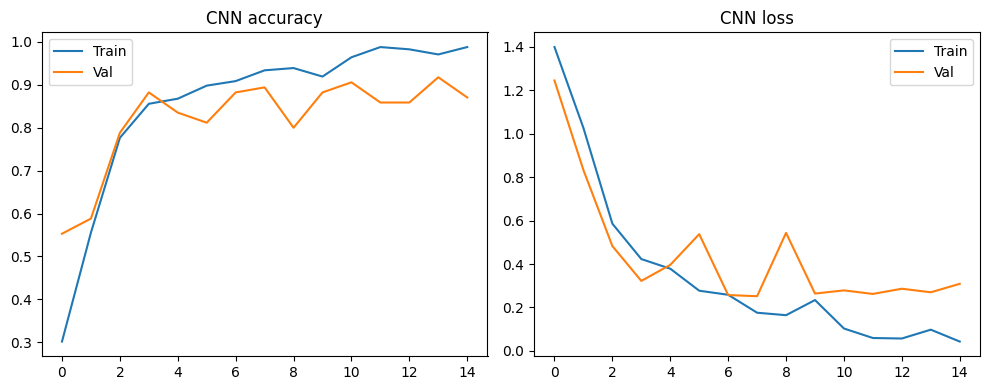


===== FINAL COMPARISON =====
Model                  Accuracy
--------------------------------
SVM                      0.9810
Random Forest            0.9810
CNN (from scratch)       0.9621


In [ ]:
# Evaluate CNN and compare with ML
cnn_loss, cnn_acc = model.evaluate(X_te, y_te, verbose=0)
print(f"CNN Accuracy: {cnn_acc:.4f}")

# Training curve
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Val")
plt.title("CNN accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Val")
plt.title("CNN loss")
plt.legend()
plt.tight_layout()
plt.savefig("cnn_training_curves.png", dpi=100)
plt.show()

# Final comparison table
print("\n===== FINAL COMPARISON =====")
print(f"{'Model':<20} {'Accuracy':>10}")
print("-" * 32)
print(f"{'SVM':<20} {svm_acc:>10.4f}")
print(f"{'Random Forest':<20} {rf_acc:>10.4f}")
print(f"{'CNN (from scratch)':<20} {cnn_acc:>10.4f}")

In [ ]:
# Transfer learning with MobileNetV2
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE_TL = 128  # MobileNetV2 works fine at 128x128

# Preprocess images for MobileNetV2 (expects [-1, 1] range)
X_tl = np.array([
    preprocess_input(cv2.resize(img, (IMG_SIZE_TL, IMG_SIZE_TL)).astype(np.float32))
    for img in images
])
y_cat_tl = to_categorical(y, num_classes=len(CLASSES))

X_tr_tl, X_te_tl, y_tr_tl, y_te_tl = train_test_split(
    X_tl, y_cat_tl, test_size=0.2, random_state=42, stratify=y
)

# Load MobileNetV2 without top, freeze base layers
base_model = MobileNetV2(
    input_shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # freeze pretrained weights

# Add custom classification head
inputs = layers.Input(shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)

tl_model = models.Model(inputs, outputs)
tl_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
tl_model.summary()

print("\nPhase 1: Training classification head only...")
history_tl = tl_model.fit(
    X_tr_tl, y_tr_tl,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Phase 1: Training classification head only...
Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 25s 492ms/step - accuracy: 0.7354 - loss: 0.6160 - val_accuracy: 0.9294 - val_loss: 0.2276
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 19s 425ms/step - accuracy: 0.9524 - loss: 0.1699 - val_accuracy: 0.9294 - val_loss: 0.1882
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 445ms/step - accuracy: 0.9643 - loss: 0.1022 - val_accuracy: 0.9529 - val_loss: 0.1764
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 441ms/step - accuracy: 0.9841 - loss: 0.0694 - val_accuracy: 0.9412 - val_loss: 0.1429
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 365ms/step - accuracy: 0.9841 - loss: 0.0603 - val_accuracy: 0.9529 - val_loss: 0.1494
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 434ms/step - accuracy: 0.9934 - loss: 0.0345 - val_accuracy: 0.9412 - val_loss: 0.1576
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 421ms/step - accuracy: 0.9960 - loss: 0.0250 - val_accuracy: 0.9412 - val_loss: 0.1921
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 447ms/ste

In [ ]:
# Fine-tune top layers of MobileNetV2
import tensorflow as tf
print("Phase 2: Fine-tuning top 30 layers of MobileNetV2...")
base_model.trainable = True

# Freeze all except last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),  # very small lr for fine-tuning
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_ft = tl_model.fit(
    X_tr_tl, y_tr_tl,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

tl_loss, tl_acc = tl_model.evaluate(X_te_tl, y_te_tl, verbose=0)
print(f"\nMobileNetV2 (fine-tuned) Accuracy: {tl_acc:.4f}")

Phase 2: Fine-tuning top 30 layers of MobileNetV2...
Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 31s 665ms/step - accuracy: 0.6561 - loss: 1.3226 - val_accuracy: 0.9412 - val_loss: 0.1834
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 22s 919ms/step - accuracy: 0.8135 - loss: 0.6091 - val_accuracy: 0.9412 - val_loss: 0.2059
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 34s 601ms/step - accuracy: 0.8743 - loss: 0.3772 - val_accuracy: 0.9412 - val_loss: 0.2281
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 14s 585ms/step - accuracy: 0.9286 - loss: 0.2201 - val_accuracy: 0.9412 - val_loss: 0.2512
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 618ms/step - accuracy: 0.9312 - loss: 0.1719 - val_accuracy: 0.9412 - val_loss: 0.2663
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 14s 595ms/step - accuracy: 0.9563 - loss: 0.1271 - val_accuracy: 0.9412 - val_loss: 0.2724
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 615ms/step - accuracy: 0.9590 - loss: 0.1159 - val_accuracy: 0.9412 - val_loss: 0.2765
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 14s 58

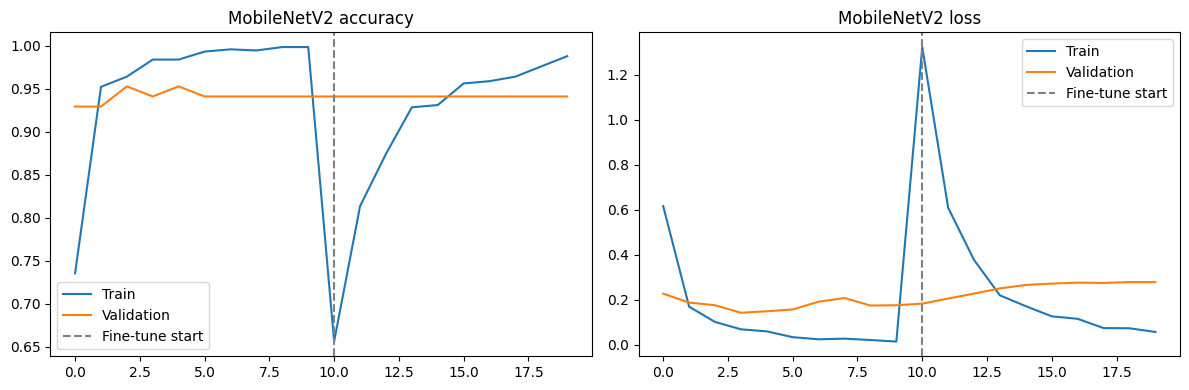

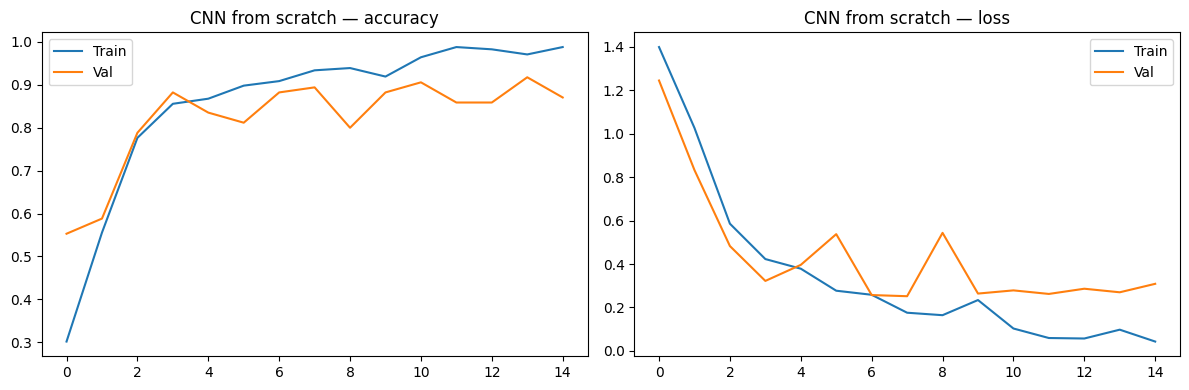


Model                       Accuracy     Type
SVM                           0.9810       ML
Random Forest                 0.9810       ML
CNN from scratch              0.9621       DL
MobileNetV2 (transfer)        0.9431       DL


In [ ]:
# Training curves + full comparison table
import tensorflow as tf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Combine phase 1 + phase 2 history
all_acc = history_tl.history["accuracy"] + history_ft.history["accuracy"]
all_val = history_tl.history["val_accuracy"] + history_ft.history["val_accuracy"]

axes[0].plot(all_acc, label="Train")
axes[0].plot(all_val, label="Validation")
axes[0].axvline(x=10, color="gray", linestyle="--", label="Fine-tune start")
axes[0].set_title("MobileNetV2 accuracy")
axes[0].legend()

axes[1].plot(history_tl.history["loss"] + history_ft.history["loss"], label="Train")
axes[1].plot(history_tl.history["val_loss"] + history_ft.history["val_loss"], label="Validation")
axes[1].axvline(x=10, color="gray", linestyle="--", label="Fine-tune start")
axes[1].set_title("MobileNetV2 loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("mobilenet_training_curves.png", dpi=100)
plt.show()

# CNN training curves
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Val")
plt.title("CNN from scratch — accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Val")
plt.title("CNN from scratch — loss")
plt.legend()
plt.tight_layout()
plt.savefig("cnn_training_curves.png", dpi=100)
plt.show()

# ===== FINAL COMPARISON TABLE =====
print("\n" + "="*45)
print(f"{'Model':<25} {'Accuracy':>10} {'Type':>8}")
print("="*45)
print(f"{'SVM':<25} {svm_acc:>10.4f} {'ML':>8}")
print(f"{'Random Forest':<25} {rf_acc:>10.4f} {'ML':>8}")
print(f"{'CNN from scratch':<25} {cnn_acc:>10.4f} {'DL':>8}")
print(f"{'MobileNetV2 (transfer)':<25} {tl_acc:>10.4f} {'DL':>8}")
print("="*45)

In [ ]:
# Install Gradio
!pip install gradio -q

In [ ]:
# Gradio GUI for real-time plant disease prediction
import gradio as gr

CLASS_NAMES = [c.replace("___", " — ") for c in CLASSES]

def predict_disease(input_img):
    # Preprocess for both models
    img_resized = cv2.resize(input_img, (IMG_SIZE, IMG_SIZE))
    img_bgr = cv2.cvtColor(img_resized, cv2.COLOR_RGB2BGR)

    # --- ML prediction (SVM) ---
    feats = extract_features(img_bgr).reshape(1, -1)
    feats_sc = scaler.transform(feats)
    svm_class = CLASSES[svm.predict(feats_sc)[0]]
    svm_label = svm_class.replace("___", " — ")

    # --- CNN prediction ---
    img_cnn = img_resized / 255.0
    img_cnn = np.expand_dims(img_cnn, axis=0)
    cnn_probs = model.predict(img_cnn, verbose=0)[0]
    cnn_class_idx = np.argmax(cnn_probs)
    cnn_label = CLASS_NAMES[cnn_class_idx]
    cnn_confidence = float(cnn_probs[cnn_class_idx])

    # --- MobileNetV2 prediction ---
    img_tl = preprocess_input(
        cv2.resize(input_img, (IMG_SIZE_TL, IMG_SIZE_TL)).astype(np.float32)
    )
    img_tl = np.expand_dims(img_tl, axis=0)
    tl_probs = tl_model.predict(img_tl, verbose=0)[0]
    tl_class_idx = np.argmax(tl_probs)
    tl_label = CLASS_NAMES[tl_class_idx]
    tl_confidence = float(tl_probs[tl_class_idx])

    # --- Segmentation visualization ---
    sobel, canny, otsu, hsv_seg, _ = segment_full(img_bgr)
    fig, axes = plt.subplots(1, 4, figsize=(14, 3))
    axes[0].imshow(input_img); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(sobel, cmap="gray"); axes[1].set_title("Sobel"); axes[1].axis("off")
    axes[2].imshow(canny, cmap="gray"); axes[2].set_title("Canny"); axes[2].axis("off")
    axes[3].imshow(cv2.cvtColor(hsv_seg, cv2.COLOR_BGR2RGB)); axes[3].set_title("HSV mask"); axes[3].axis("off")
    plt.tight_layout()

    result = (
        f"SVM prediction:          {svm_label}\n"
        f"CNN prediction:          {cnn_label}  ({cnn_confidence*100:.1f}%)\n"
        f"MobileNetV2 prediction:  {tl_label}  ({tl_confidence*100:.1f}%)"
    )

    return fig, result

# Launch the interface
demo = gr.Interface(
    fn=predict_disease,
    inputs=gr.Image(type="numpy", label="Upload a leaf image"),
    outputs=[
        gr.Plot(label="Segmentation results"),
        gr.Textbox(label="Predictions (SVM / CNN / MobileNetV2)", lines=4)
    ],
    title="Plant Disease Detector",
    description="Upload a leaf image — get predictions from 3 models + segmentation visualization.",
    examples=[]
)

demo.launch(share=True)  # share=True gives you a public URL valid for 72h

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://60ba2322cd9f1e085b.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Download all saved figures
from google.colab import files
for fig in ["preprocessing_results.png", "segmentation_comparison.png",
            "SVM_Confusion_Matrix.png", "Random_Forest_Confusion_Matrix.png",
            "cnn_training_curves.png", "mobilenet_training_curves.png"]:
    files.download(fig)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>